In [18]:
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn import linear_model
import matplotlib.patches as mpatches
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from haptools.data import GenotypesTR, GenotypesVCF
from gene_model_pred import GeneExpressionPredictor
from model_sims import load_genotypes, train_models_simulated_data

header_file = "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/train_data/EUR_normalized_and_filtered_hg38.csv"
expr_file = "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/train_data/EUR_normalized_filtered_final_residuals_hg38.csv"
snp_file = "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/SNP_vcfs/SNP_{chrom}_filtered.vcf.gz"
str_file = "/gymreklab-tscc/mlamkin/GeneExprPredictor_data/STR_vcfs/ensemble_{chrom}_filtered.vcf.gz"

snp_model_color = (244/256, 179/256, 1/256)
snp_tr_model_color = (219/256, 16/256, 72/256)

In [ ]:
# NOTE see model_sims.py for simulation code

# Simulation Overview
# 1. Collect existing Genotypes from TRs and SNPs
# 2. Simulate Expression using the Genotypes fro two different cases
#   a. Big TR (Use TIMM10 GTs)
#   b. Multiple TRs and SNPs with evenly distributed heritability explained (Update h2_SNP and h2_TR for drawing coeff size of each for simulated expression)
# p = probability of TR being causal (effect size) coeff = N(0, h2_SNP/Mp) M = total SNPs used to draw coeff size

In [2]:
def plot_rsq_barplot(large_var_sim_rsq_dict, output):
    sim_labels = []
    sim_vals = []
    sim_stds = [] # 2*Std deviation for ~95% CI
    box_locs = []
    x_ticks = []
    gain = []

    for key_ind, key in enumerate(large_var_sim_rsq_dict.keys()):
        het_info = key.split('_')
        snp_h2 = het_info[2]
        tr_h2 = het_info[4]
        sim_labels.append(f"SNP h2: {snp_h2}, TR h2: {tr_h2}")
        simulated_rsq = np.array(large_var_sim_rsq_dict[key])
        simulated_rsq[simulated_rsq < 0] = 0

        ### For using the mean of SNP model and SNP+TR model Rsqs ###
        sim_vals.append(np.mean(simulated_rsq[:,0]))
        sim_vals.append(np.mean(simulated_rsq[:,1]))
        gain.append(np.mean(simulated_rsq[:,1]) - np.mean(simulated_rsq[:,0]))
        sim_stds.extend([2*np.std(simulated_rsq[:,0]), 2*np.std(simulated_rsq[:,1])])
        box_locs.extend([key_ind*2+1, key_ind*2+1.8])
        x_ticks.extend([key_ind*2+1.4])

    print("SNP+TR - SNP only Mean Gain")
    print(np.mean(gain))
    print(sim_vals)

    # Barplot
    fig = plt.figure(figsize=(8,6))
    ax = fig.add_subplot(1,1,1)
    #ax.set_title("Heritability 0.80 SNP vs SNP+TR Model Simulations")
    ax.set_ylabel('Adjusted R-squared')

    snp_boxes = ax.bar(
        box_locs,
        sim_vals,
        color=[snp_model_color, snp_tr_model_color],
        yerr=sim_stds,
        capsize=5,
    )

    handles = [
        mpatches.Patch(color=snp_model_color, label='SNP Model'),
        mpatches.Patch(color=snp_tr_model_color, label='SNP+TR Model')
    ]
    ax.legend(handles=handles)
    ax.set_ylim(0,1)
    ax.set_xticks(
        x_ticks, 
        sim_labels,
        ha='right'
    )
    ax.tick_params(axis='x', labelrotation=60)
    fig.savefig(output, bbox_inches='tight')
    fig.show()

## Case 1. One TR with Large Heritability (Figure 1.)

SNP+TR - SNP only Gain
0.05652382269418859
[np.float64(9.27873880462915e-05), np.float64(0.0), np.float64(0.25245625388106274), np.float64(0.29093050107815854), np.float64(0.4161381615065848), np.float64(0.4720420194291606), np.float64(0.5123254826679067), np.float64(0.5758618000213677), np.float64(0.5754721191469421), np.float64(0.6432544130284422), np.float64(0.6288241354434216), np.float64(0.697802560668091), np.float64(0.664278086269144), np.float64(0.7347951485495824), np.float64(0.6941228203487168), np.float64(0.7634253966635111), np.float64(0.7137500162891424), np.float64(0.7880624277503512)]


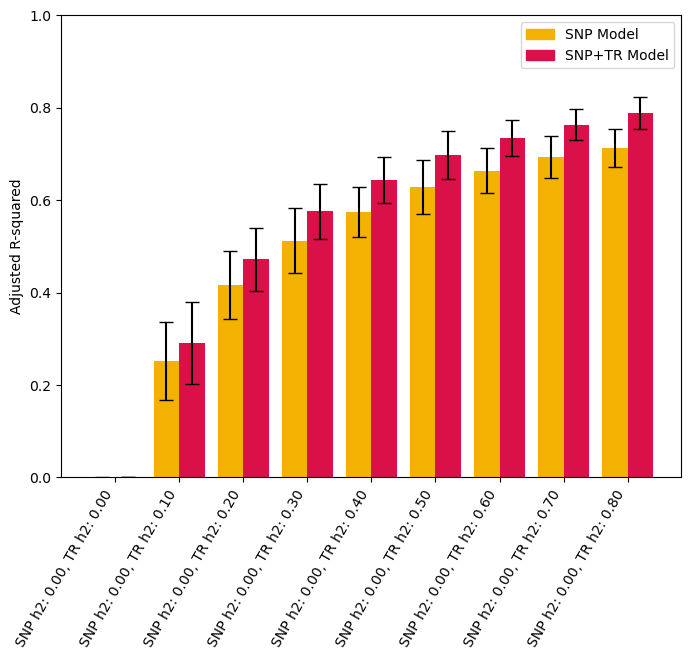

In [11]:
%matplotlib inline

# Causal SNP chosen
#    ('11:57166365:C:T', 'chr11', 57166365, ('C', 'T'))
# Causal TR chosen
#    (chr11:57528484)

# Load simulated data
with open("/storage/mlamkin/data/GeneExprPredictor/paper_figures/single_causal_var_sim_rsq.json", 'r') as json_file:
    large_var_sim_rsq_dict = json.load(json_file)

large_var_sim_rsq_dict = {key:large_var_sim_rsq_dict[key] for key in large_var_sim_rsq_dict.keys() if 'adj' in key}

output = f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/Single_TR_Simulation_Barplot.pdf"
plot_rsq_barplot(large_var_sim_rsq_dict, output)

## Case 2. Multiple High LD Heritability Explained on TRs (Supplementary)

[np.float64(0.8270296805068398), np.float64(0.8265812996293128), np.float64(0.84514101130195), np.float64(0.8479242004990281), np.float64(0.8454561343276965), np.float64(0.8497853238979622), np.float64(0.8483904850683716), np.float64(0.8558499976999744), np.float64(0.8534730296508024), np.float64(0.8629103321328339), np.float64(0.8442252718239187), np.float64(0.8556609201268449), np.float64(0.8358830727207434), np.float64(0.8531017339815778), np.float64(0.8265503869603757), np.float64(0.8499095479918636), np.float64(0.7991135460820182), np.float64(0.834971163180229)]


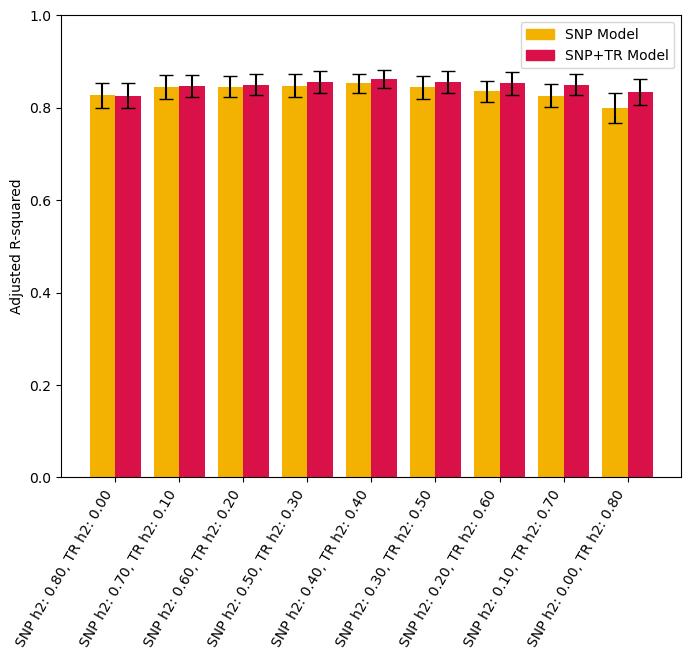

In [3]:
%matplotlib inline

# Causal SNPs chosen: 
# ('17:82596912:C:A', 'chr17', 82596912, ('C', 'A'))
# ('17:82872389:G:A', 'chr17', 82872389, ('G', 'A'))
# ('17:82101611:C:T', 'chr17', 82101611, ('C', 'T'))
# ('17:82134719:G:A', 'chr17', 82134719, ('G', 'A'))
# Causal TRs chosen: 
# ('None', 'chr17', 82603720) 
# ('None', 'chr17', 82879060)
# ('None', 'chr17', 82210518) 
# ('None', 'chr17', 82210518)
# LD between causal SNPs and TRs: [0.92817    0.94094752 0.9122075  0.91294388]

# Load simulated data
with open("/storage/mlamkin/data/GeneExprPredictor/paper_figures/multi_causal_var_high_LD_rsq.json", 'r') as json_file:
    multi_var_sim_rsq_dict = json.load(json_file)

multi_var_sim_rsq_dict = {key:multi_var_sim_rsq_dict[key] for key in multi_var_sim_rsq_dict.keys() if 'adj' in key}

output = f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/Multi_TR_high_LD_Simulation_Barplot.pdf"
plot_rsq_barplot(multi_var_sim_rsq_dict, output)

## Case 3. Multi with 4 SNPs and 4 TRs (Randomly Selected Every Simulation) (Fig1 of Paper)

[np.float64(0.7532677113057352), np.float64(0.7508595623601062), np.float64(0.6775913602045962), np.float64(0.710368570350458), np.float64(0.6146212121110086), np.float64(0.6909089524817188), np.float64(0.5684822495676991), np.float64(0.6971254117103639), np.float64(0.5140520758579883), np.float64(0.6847425775988298), np.float64(0.43461618545217023), np.float64(0.6744082784734453), np.float64(0.39926797737391423), np.float64(0.6819751337769755), np.float64(0.3788334191047879), np.float64(0.6775132280102599), np.float64(0.36744283530747684), np.float64(0.7123720406881815)]


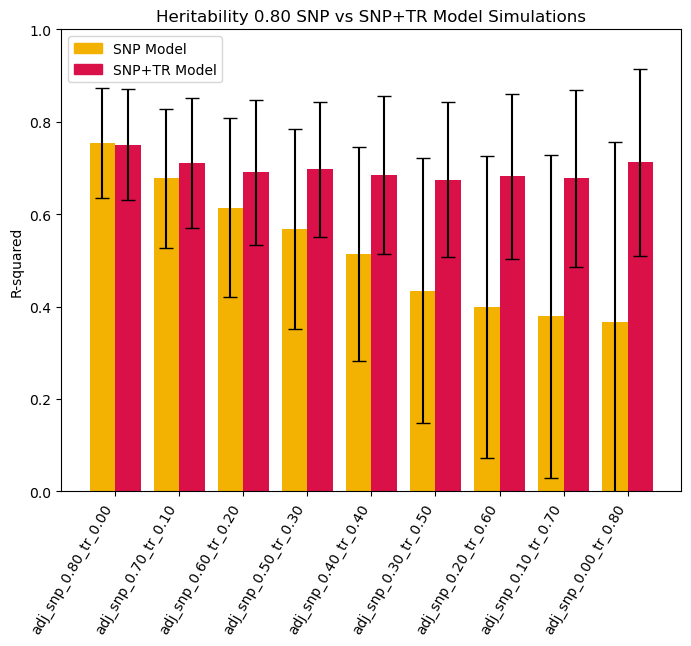

In [6]:
%matplotlib inline

# Load simulated data
with open("/storage/mlamkin/data/GeneExprPredictor/paper_figures/multi_causal_var_sim_4_snps_4_trs_rsq.json", 'r') as json_file:
    multi_var_sim_rsq_dict = json.load(json_file)

multi_var_sim_rsq_dict = {key:multi_var_sim_rsq_dict[key] for key in multi_var_sim_rsq_dict.keys() if 'adj' in key}

output = f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/Multi_TR_4_SNPs_4_TRs_Simulation_Barplot.pdf"
plot_rsq_barplot(multi_var_sim_rsq_dict, output)

## Supplementary. Multi Low LD Simulations (<0.2) 

SNP+TR - SNP only Mean Gain
0.13549778814770214
[np.float64(0.7377383240095238), np.float64(0.7363416613520155), np.float64(0.7046547947636952), np.float64(0.7399451244048322), np.float64(0.676683157354027), np.float64(0.7498202855565045), np.float64(0.6515569544816066), np.float64(0.7581854228220967), np.float64(0.628719462034822), np.float64(0.7591821589022385), np.float64(0.6003627298575576), np.float64(0.7680206357448348), np.float64(0.5671679551721415), np.float64(0.7694028350595953), np.float64(0.5410837883160304), np.float64(0.7705741219445963), np.float64(0.5113723824598563), np.float64(0.7873473959918659)]


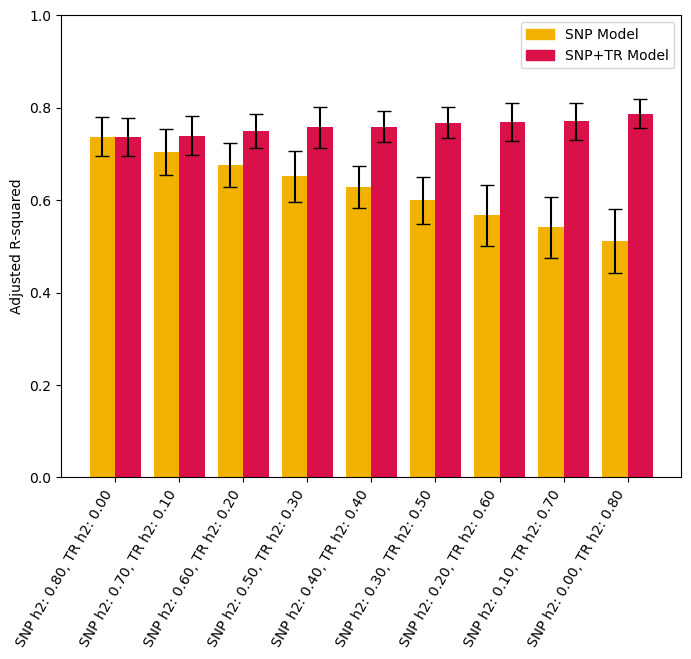

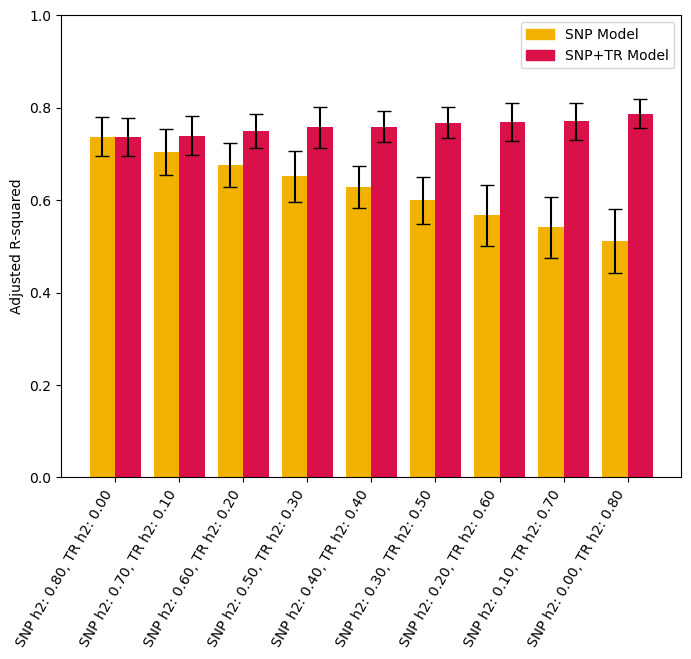

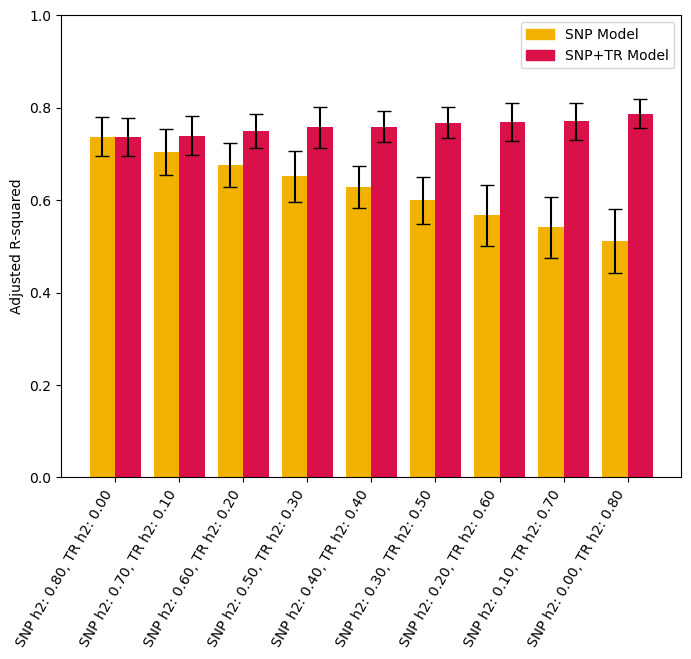

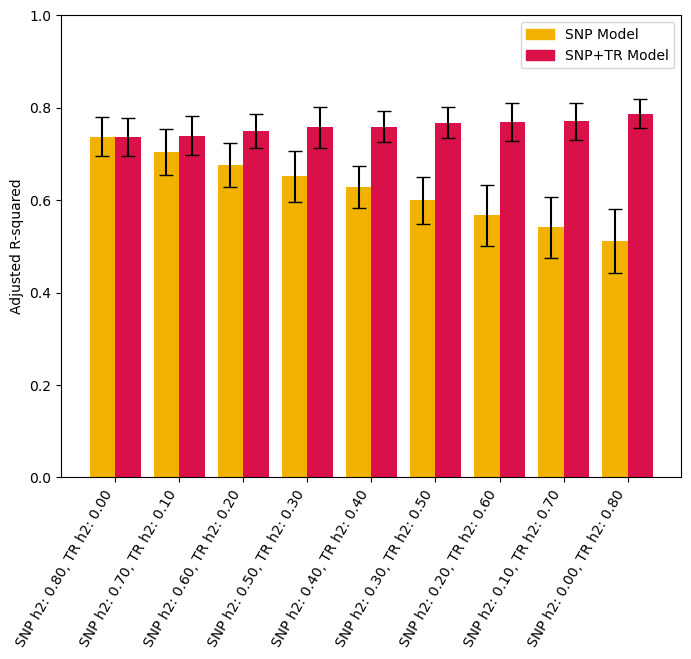

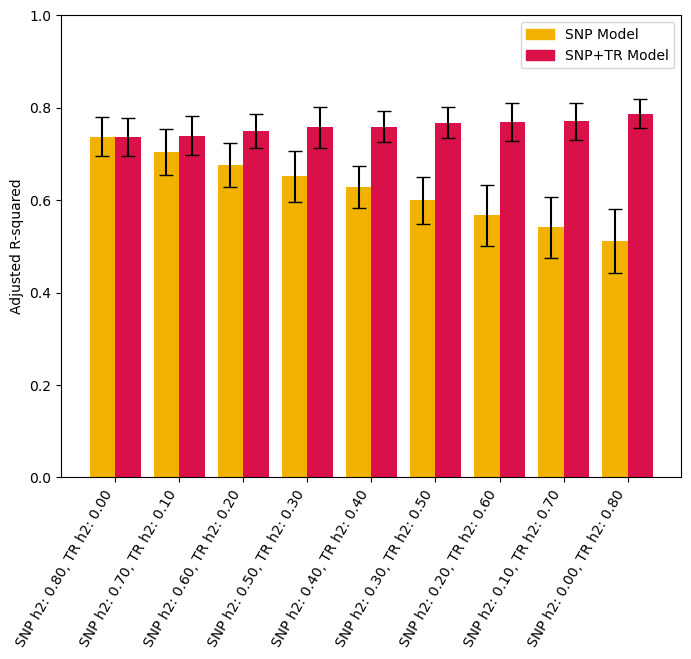

In [30]:
%matplotlib inline

# Causal SNPs chosen: 
# ('17:82044620:T:A', 'chr17', 82044620, ('T', 'A'))
# ('17:82504059:C:T', 'chr17', 82504059, ('C', 'T'))
# ('17:82412549:A:G', 'chr17', 82412549, ('A', 'G'))
# ('17:82503792:C:T', 'chr17', 82503792, ('C', 'T'))
# Causal TRs chosen: 
# ('None', 'chr17', 82071841) 
# ('None', 'chr17', 82574322)
# ('None', 'chr17', 82422496) 
# ('None', 'chr17', 82123123)]
# LD between causal SNPs and TRs: [0.05885616 0.03395486 0.0990673  0.02830501]

# Load simulated data
with open("/storage/mlamkin/data/GeneExprPredictor/paper_figures/multi_causal_var_low_LD_rsq.json", 'r') as json_file:
    multi_var_sim_rsq_dict = json.load(json_file)

multi_var_sim_rsq_dict = {key:multi_var_sim_rsq_dict[key] for key in multi_var_sim_rsq_dict.keys() if 'adj' in key}

output = f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/Multi_TR_low_LD_Simulation_Barplot.pdf"
plot_rsq_barplot(multi_var_sim_rsq_dict, output)


## Supplementary. Multi with 2 SNPs and 2 TRs (Randomly Selected Every Simulation)

[np.float64(0.7630812915992996), np.float64(0.761879642868028), np.float64(0.6893766557408747), np.float64(0.7332188727709381), np.float64(0.6399851538391073), np.float64(0.729249855278348), np.float64(0.5998147990789043), np.float64(0.7321667596766569), np.float64(0.5567591401822988), np.float64(0.7212092021161619), np.float64(0.5205254336023589), np.float64(0.7242235205553823), np.float64(0.43614048391100835), np.float64(0.7084490627433294), np.float64(0.4459154844634281), np.float64(0.7112382803052831), np.float64(0.4000936755078174), np.float64(0.7003456849699979)]


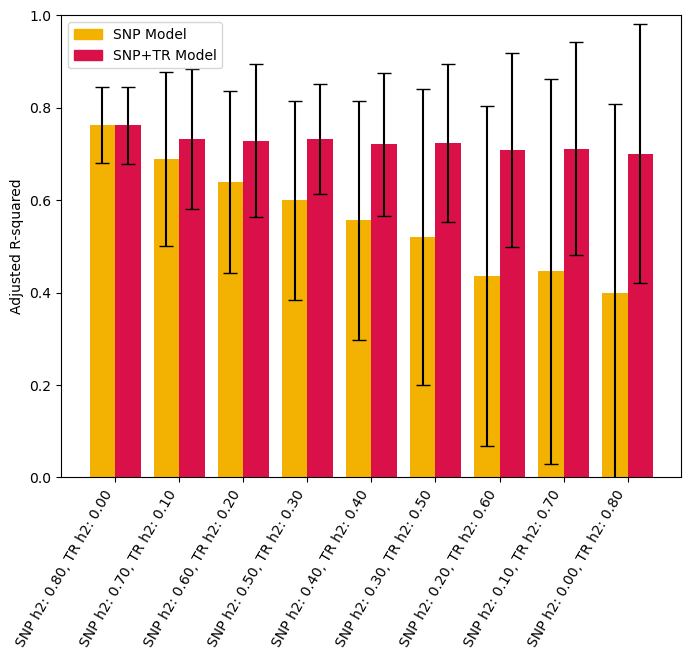

In [9]:
%matplotlib inline

# Load simulated data
with open("/storage/mlamkin/data/GeneExprPredictor/paper_figures/multi_causal_var_sim_2_SNPs_2_TRs_rsq.json", 'r') as json_file:
    multi_var_sim_rsq_dict = json.load(json_file)

multi_var_sim_rsq_dict = {key:multi_var_sim_rsq_dict[key] for key in multi_var_sim_rsq_dict.keys() if 'adj' in key}

output = f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/Multi_TR_2_SNPs_2_TRs_Simulation_Barplot.pdf"
plot_rsq_barplot(multi_var_sim_rsq_dict, output)

## Supplementary. TR Heritability vs Gain between SNP+TR Model and SNP only model

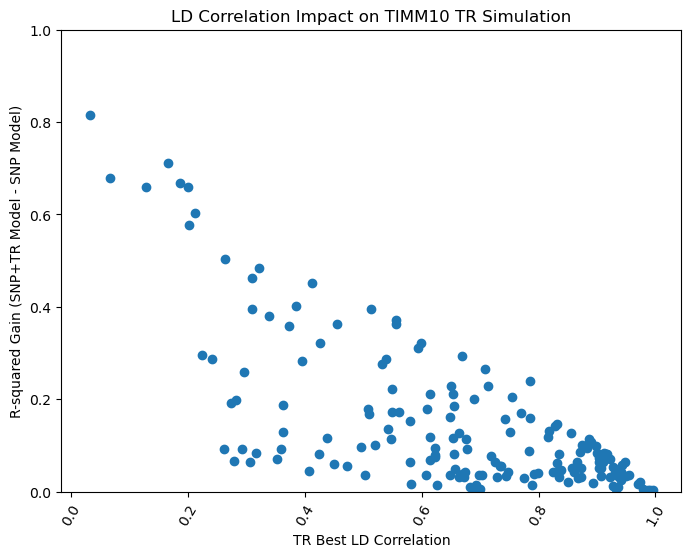

In [3]:
%matplotlib inline

# Given a single causal TR with heritability 0.8 plot how heritability 
with open("/storage/mlamkin/data/GeneExprPredictor/paper_figures/TIMM10_trs_gain_ld_simulations.json", 'r') as json_file:
    ld_rsq_dict = json.load(json_file)
# Barplot
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(1,1,1)
ax.set_title("LD Correlation Impact on TIMM10 TR Simulation")
ax.set_ylabel('R-squared Gain (SNP+TR Model - SNP Model)')
ax.set_xlabel('TR Best LD Correlation')
snp_boxes = ax.scatter(
    ld_rsq_dict['LD_correlation'],
    ld_rsq_dict['gain'],
)

ax.set_ylim(0,1)
ax.tick_params(axis='x', labelrotation=60)
#fig.savefig(f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/TIMM10_LD_correlation_simulations.pdf", bbox_inches='tight') # TODO update
fig.show()


### Ball and Stick Plots

In [8]:
import os
import json
import pickle
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import wilcoxon
from haptools.data import Genotypes
from gene_model_pred import GeneExpressionPredictor
import matplotlib as mpl
import matplotlib.pyplot as plt 
import matplotlib.cm as cm
import matplotlib.patches as mpatches
from matplotlib.colors import LogNorm

# Colors for each plot
snp_model_color = (244/256, 179/256, 1/256)
snp_tr_model_color = (219/256, 16/256, 72/256)
snp_color = (46/256, 37/256, 133/256)
tr_color = (51/256, 117/256, 56/256)
eur_color = tr_color
afr_color = (88/256, 9/256, 79/256)

# NOTE Important so when loading figures into illustrator the text is seen as text
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42 

h2_threshold = 0.05/12605 # 12605 is the number of nonzero genes in our Geuvadis expression table
master_table = "/storage/mlamkin/data/GeneExprPredictor/Geuvadis_master_table.txt"
gtex_table = "/storage/mlamkin/data/GeneExprPredictor/GTEx_predicted_results.txt"
#master_table = "/expanse/projects/gymreklab/mlamkin/GeneExprPredictor_data/final_results/Geuvadis_master_table.txt"
#gusev_EBV_data = "/storage/mlamkin/data/GeneExprPredictor/gusev_results/Gusev_all_genes_EBV-transformed_lymphocytes.txt"

def plot_coeff_comparison(
    gene_name,
    chrom,
    tss_start,
    tss_end,
    tss_strand,
    snp_coords,
    snp_coeffs,
    tr_coords,
    tr_coeffs,
    output,
):
    fig = plt.figure(figsize=(16,12))
    ax = fig.add_subplot(1,1,1)
    ax.set_title(f"{gene_name} Simulated Coefficient Comparison")
    ax.set_ylabel("Simulated Heritability")

    training_boundary = (tss_start-500000, tss_end+500000)
        
    # Plot TSS start and end keeping account of strand orientation
    # Find where true gene start is based on strand
    if tss_strand == '+':
        gene_start = tss_start
        gene_end = tss_end
        dir = 1
    else:
        gene_start = tss_end
        gene_end = tss_start
        dir = -1
    
    # Plot an arrow for gene start
    ax.plot([gene_start, gene_start], [-0.02, 0.02], color='black')
    ax.annotate("", xy=(gene_start + (dir*20000), 0.02), xytext=(gene_start, 0.02),
            arrowprops=dict(arrowstyle="->"))

    # Plot end of gene
    ax.plot([gene_end, gene_end], [-0.02, 0.02], color='black')

    # Plot top SNPs
    if len(snp_coords) != 0:
        ax.scatter(snp_coords, np.abs(snp_coeffs), color=snp_color, s=100)
        ax.vlines(snp_coords, 0, np.abs(snp_coeffs), color='black', linestyle="dashed")
        ax.scatter(snp_coords, -1*np.abs(snp_coeffs), color=snp_color, label='SNP', s=100)
        ax.vlines(snp_coords, 0, -1*np.abs(snp_coeffs), color='black', linestyle="dashed")
 
    # Plot bot SNPs and TRs
    ax.scatter(tr_coords, -1*np.abs(tr_coeffs), color=tr_color, label=f"TR", s=100)
    ax.vlines(tr_coords, 0, -1*np.abs(tr_coeffs), color='black', linestyle="dashed")
    ax.plot(
        [
            training_boundary[0],
            training_boundary[1]
        ], 
        [0,0], 
        color='black',
    )

    # Set Plot Limits
    ax.set_xlim(training_boundary)
    ax.set_xlabel(f"{chrom} Coords")
    ylim_bound = 0.8
    ax.set_ylim(-1*ylim_bound-0.01, ylim_bound+0.01)

    ax.legend()
    fig.savefig(output)
    return

def ball_and_stick(
    gene_id, 
    gene_name, 
    chrom,
    snp_coords,
    snp_coeffs,
    tr_coords, 
    tr_coeffs,
    output,
):
    # Load gene start and end coordinates
    TSS_file = "/storage/mlamkin/data/GeneExprPredictor/train_data/GRCh38_V38_TSS.tsv"
    TSS_df = pd.read_csv(TSS_file, delimiter='\t', usecols=['strand', 'name2'])
    TSS_df.columns = ['strand', 'gene']
    TSS_gene = TSS_df[TSS_df['gene'] == gene_name]
    strand = '+'
    try:
        strand = TSS_gene['strand'].iloc[0]
    except:
        print(f"Could not find strand orientation for gene: {gene_name} (Assuming '+' Direction)")

    # Load required genotypes and gene expression to collect coefficients
    #path = "/expanse/projects/gymreklab/mlamkin/" # Use for Expanse
    path = "/gymreklab-tscc/mlamkin/" # Use for Snorlax
    EUR_header_file = path + "GeneExprPredictor_data/train_data/EUR_normalized_and_filtered_hg38.csv"

    # Load gene start and end
    gene_info_df = pd.read_csv(EUR_header_file, delimiter='\t', usecols=['start', 'end', 'gene_id'])
    gene_info_df['gene_id'] = gene_info_df['gene_id'].str.split('.').str[0]
    gene_info = gene_info_df[gene_info_df['gene_id'] == gene_id]
    gene_start = gene_info['start'].iloc[0] 
    gene_end = gene_info['end'].iloc[0] 

    plot_coeff_comparison(
        gene_name,
        chrom,
        gene_start,
        gene_end,
        strand,
        snp_coords,
        snp_coeffs,
        tr_coords,
        tr_coeffs,
        output=output,
    )

def main():
    single_var_output = f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/TIMM10_simulated_single_tr_model_coefficient_comparison.pdf"
    multi_var_output = f"/storage/mlamkin/data/GeneExprPredictor/paper_figures/HEXDC_simulated_multi_tr_ld_model_coefficient_comparison.pdf"
    snp_data = {'single_snp':[], 'single_snp_coeff':[0], 'multi_snp':[82522165, 82878548, 82821347, 82532424], 'multi_snp_coeff':[0.1,0.1,0.1,0.1]}
    tr_data = {'single_tr':[57528484], 'single_tr_coeff':[0.8], 'multi_tr':[82603720, 82210518, 82753869, 81950288], 'multi_tr_coeff':[0.1,0.1,0.1,0.1]}
    TIMM10_chrom = 'chr11'
    HEXDC_chrom = 'chr17'

    ball_and_stick('ENSG00000134809', 'TIMM10', TIMM10_chrom, snp_data['single_snp'], snp_data['single_snp_coeff'], tr_data['single_tr'], tr_data['single_tr_coeff'], single_var_output)
    ball_and_stick('ENSG00000169660', 'HEXDC', HEXDC_chrom, snp_data['multi_snp'], snp_data['multi_snp_coeff'], tr_data['multi_tr'], tr_data['multi_tr_coeff'], multi_var_output)


if __name__ == '__main__':
    main()

Could not find strand orientation for gene: HEXDC (Assuming '+' Direction)


## LD Variation Testing

### Experiment 1. Vary LD Threshold

In [17]:
# LD Threshold
ld_thresh = 0.1

# Load all GTs
region = "chr17:81918376-82942639"
all_snp_gts, all_snp_vars = load_genotypes(region, 'chr17')
all_tr_gts, all_tr_vars = load_genotypes(region, 'chr17', variant_type='TR')
all_gts = np.concatenate((all_snp_gts, all_tr_gts), axis=1)

# Calculate LD matrix of SNPs and TRs and collect max LD between SNPs and TRs
ld_matrix = np.corrcoef(np.transpose(all_gts))**2
snp_correlations = ld_matrix[:all_snp_gts.shape[1],all_snp_gts.shape[1]:]
snp_tr_max_ld = np.max(snp_correlations, axis=1)
max_tr_locs = np.argmax(snp_correlations, axis=1)
snp_low_ld_locs = np.argwhere(snp_tr_max_ld < ld_thresh)

# Grab from list randomly selected SNPs and corresponding low LD TRs
causal_snp_inds = np.random.choice(snp_low_ld_locs.flatten(), replace=False, size=4)
causal_tr_inds = max_tr_locs[causal_snp_inds]

print(f"Causal SNPs chosen: {all_snp_vars[causal_snp_inds]}")
print(f"Causal TRs chosen: {all_tr_vars[causal_tr_inds]}")
print(f"LD between causal SNPs and TRs: {snp_tr_max_ld[causal_snp_inds]}")

causal_snp_gts = all_snp_gts[:,causal_snp_inds]
causal_tr_gts = all_tr_gts[:,causal_tr_inds]
causal_gts = np.concatenate((causal_snp_gts, causal_tr_gts), axis=1)

# 2. Parameters for Simulation
test_var_sim_rsq_dict = train_models_simulated_data(
    causal_snp_gts,
    causal_tr_gts,
    causal_gts,
    all_snp_gts,
    all_gts,
    num_simulations=1,
    all_h2=0.8,
    h2_start=0.8,
    #randomize_samples=True,
)

print(test_var_sim_rsq_dict)

Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!
Samples cannot be loaded in a particular order. Use subset() to reorder the samples after loading them.
The max_variants parameter was not specified. We have no choice but to append to an ever-growing array, which can lead to memory overuse!


Causal SNPs chosen: [('17:82312692:AT:A', 'chr17', 82312692, ('AT', 'A'))
 ('17:82055121:A:G', 'chr17', 82055121, ('A', 'G'))
 ('17:81960957:G:A', 'chr17', 81960957, ('G', 'A'))
 ('17:81984994:A:AC', 'chr17', 81984994, ('A', 'AC'))]
Causal TRs chosen: [('None', 'chr17', 82312692) ('None', 'chr17', 82281682)
 ('None', 'chr17', 81968632) ('None', 'chr17', 82001975)]
LD between causal SNPs and TRs: [0.09624164 0.06969992 0.09609466 0.09612925]
Simulation Number: 0
Unadjusted: 0.44979579389675145 0.7491032506741436 Adjusted: 0.42573438546658016 0.7326754873254269
Simulation Number: 1
Unadjusted: 0.4918412489220539 0.7755998857842338 Adjusted: 0.4419606353193106 0.7601933107783752
Simulation Number: 2
Unadjusted: 0.5192821856004141 0.7955096381688856 Adjusted: 0.4847395881585276 0.7865669109751051
Simulation Number: 3
Unadjusted: 0.4471481839087634 0.7921056036420051 Adjusted: 0.42962262201538126 0.7891609238069061
Simulation Number: 4
Unadjusted: 0.478074408080657 0.7994430872123631 Adjust

## FAM167A Allele Distribution of Top TRs

In [25]:
# FAM167A ENSG00000154319 chr8
gene = 'FAM167A'

geuv_assoc_df = pd.read_csv(
    "/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_chr8_associations_with_metadata.csv", 
    delimiter=',', 
    usecols=[
        'gene',
        'gene_name',
        'chrom',
        'str.start',
        'p.linear',
        'corrected_p.linear',
        'afreq_EUR',
        'het_EUR',
        'repeat_unit'
    ]
)

gene_assoc_df = geuv_assoc_df[geuv_assoc_df['gene_name'] == gene]
sig_gene_assoc_df = gene_assoc_df[gene_assoc_df['corrected_p.linear'] <= 0.05]


sig_gene_assoc_df.to_csv(f'/storage/mlamkin/data/NonLinearSTRExpression/paper_tables/Geuvadis_{gene}_sig_linear_trs.csv', index=False)
